# EDA com downloads — clima de Brasília (INMET A001, 2014–2023)

**João Victor Uchôa** · Análise e Visualização de Dados · CESAR School 2026.2

Este notebook é a versão "com downloads" da minha EDA da Aula 11 ([eda.ipynb](eda.ipynb), mantido como foi entregue).
Ele faz três coisas:

1. **Carrega o dado bruto** — o mesmo `clima_brasilia.csv` usado na EDA (estação automática A001 – Brasília, dados
   horários de temperatura, umidade relativa e precipitação). Se o arquivo não estiver em `data/raw/`, há uma célula
   opcional que reconstrói o CSV a partir dos arquivos anuais do portal de dados históricos do INMET.
2. **Repete os tratamentos da EDA** (sentinela `-9999` → `NaN`, sem remover outliers) e confere se os números batem
   com os da Aula 11.
3. **Prepara o dado para o app** (fuso horário, calendário, variáveis derivadas) e **exporta** `data/clean/dataset.csv`.

> As decisões de tratamento são as da EDA original. O que é novo aqui (conversão para hora local, ponto de orvalho,
> período seco/chuvoso) está marcado como **acréscimo** e justificado na própria célula.

## Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# O notebook pode ser executado a partir da raiz do repositório ou de dentro de notebooks/
RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
CAMINHO_BRUTO = RAIZ / "data" / "raw" / "clima_brasilia.csv"
CAMINHO_LIMPO = RAIZ / "data" / "clean" / "dataset.csv"

COLUNAS = ["temperatura", "umidade", "precipitacao"]
SENTINELA_INMET = -9999
plt.rcParams["figure.figsize"] = (10, 4)

## 1. Dado bruto

O arquivo `clima_brasilia.csv` tem uma linha por hora com `datetime`, `ano_arquivo` (ano do arquivo anual do INMET
de onde o registro veio), `temperatura` (°C, bulbo seco), `umidade` (umidade relativa, %) e `precipitacao`
(mm na hora).

**Download opcional.** A célula abaixo só roda se o CSV não existir. Ela segue o script de coleta apresentado na
Aula 07 (download dos arquivos anuais em `portal.inmet.gov.br/uploads/dadoshistoricos/{ano}.zip`, estação A001).
Cada zip tem dezenas de MB, então a reconstrução é lenta e depende de rede.

In [2]:
def reconstruir_do_inmet(anos=range(2014, 2024), estacao="A001"):
    """Baixa os arquivos anuais do INMET e monta o CSV no mesmo formato usado na EDA."""
    import io
    import zipfile

    import requests

    partes = []
    for ano in anos:
        url = f"https://portal.inmet.gov.br/uploads/dadoshistoricos/{ano}.zip"
        resposta = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=300)
        resposta.raise_for_status()
        with zipfile.ZipFile(io.BytesIO(resposta.content)) as z:
            nome = next(n for n in z.namelist() if f"_{estacao}_" in n.upper())
            with z.open(nome) as f:
                bruto = pd.read_csv(f, sep=";", skiprows=8, encoding="latin-1", decimal=",")
        bruto.columns = [c.strip() for c in bruto.columns]
        col_data = next(c for c in bruto.columns if c.upper().startswith("DATA"))
        col_hora = next(c for c in bruto.columns if c.upper().startswith("HORA"))
        hora = bruto[col_hora].astype(str).str.replace(" UTC", "").str.replace(":", "").str[:4].str.zfill(4)
        data = pd.to_datetime(bruto[col_data].astype(str).str.replace("/", "-"))
        partes.append(pd.DataFrame({
            "datetime": data + pd.to_timedelta(hora.str[:2].astype(int), unit="h"),
            "ano_arquivo": ano,
            "temperatura": bruto["TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)"],
            "umidade": bruto["UMIDADE RELATIVA DO AR, HORARIA (%)"],
            "precipitacao": bruto["PRECIPITAÇÃO TOTAL, HORÁRIO (mm)"],
        }))
    df = pd.concat(partes, ignore_index=True)
    # A EDA usou apenas as horas com temperatura registrada
    return df.dropna(subset=["temperatura"])


if not CAMINHO_BRUTO.exists():
    reconstruir_do_inmet().to_csv(CAMINHO_BRUTO, index=False)

df = pd.read_csv(CAMINHO_BRUTO)
df.head()

,datetime,ano_arquivo,temperatura,umidade,precipitacao
0,2014-01-01 00:00:00,2014,21.2,82,0.0
1,2014-01-01 01:00:00,2014,20.3,91,0.0
2,2014-01-01 02:00:00,2014,19.9,91,0.0
3,2014-01-01 03:00:00,2014,19.9,90,0.0
4,2014-01-01 04:00:00,2014,19.4,95,0.0


In [3]:
df.shape

(87582, 5)

## 2. Tratamentos da EDA (Aula 11)

Mesmas decisões do notebook original:

- não há linhas duplicadas;
- `-9999` é o código do INMET para "sem leitura" → vira `NaN` (não invento valores);
- outliers **não** são removidos: em dados de clima, extremos podem ser reais.

In [4]:
print("duplicadas:", df.duplicated().sum())
print("sentinelas -9999:", (df[COLUNAS] == SENTINELA_INMET).sum().to_dict())

df[COLUNAS] = df[COLUNAS].replace(SENTINELA_INMET, np.nan)
df[COLUNAS].isna().sum()

duplicadas: 0
sentinelas -9999: {'temperatura': 0, 'umidade': 20, 'precipitacao': 21}


temperatura      0
umidade         20
precipitacao    21
dtype: int64

### Conferência com a EDA original

Se o dado é o mesmo da Aula 11, estes números precisam bater com os do `eda.ipynb`: 87.582 linhas,
temperatura média 21,59 °C, umidade média 64,43 %, correlação temperatura × umidade de −0,68 e chuva
acumulada de 2.023,2 mm em 2021.

In [5]:
dt_arquivo = pd.to_datetime(df["datetime"])
conferencia = {
    "linhas": len(df),
    "temperatura_media": round(df["temperatura"].mean(), 2),
    "umidade_media": round(df["umidade"].mean(), 2),
    "corr_temp_umid": round(df["temperatura"].corr(df["umidade"]), 2),
    "chuva_2021_mm": round(df.loc[dt_arquivo.dt.year == 2021, "precipitacao"].sum(), 1),
}
assert conferencia == {
    "linhas": 87582,
    "temperatura_media": 21.59,
    "umidade_media": 64.43,
    "corr_temp_umid": -0.68,
    "chuva_2021_mm": 2023.2,
}, conferencia
conferencia

{'linhas': 87582,
 'temperatura_media': np.float64(21.59),
 'umidade_media': np.float64(64.43),
 'corr_temp_umid': np.float64(-0.68),
 'chuva_2021_mm': np.float64(2023.2)}

## 3. Acréscimo: fuso horário

Os arquivos do INMET registram a hora em **UTC** (coluna "Hora UTC" nos arquivos originais). Na EDA eu analisei a
hora como veio, e por isso o pico de temperatura apareceu às 17h–18h. Em hora de Brasília (UTC−3) esse pico é
às **14h–15h**, o que é o esperado para o ciclo diário.

Como o Dashboard 2 fala de horários do dia para um público não técnico, converto para hora local com deslocamento
fixo de −3 h (hora oficial de Brasília, sem horário de verão, que foi extinto em 2019).

Consequência: as 3 primeiras horas de 01/01/2014 UTC caem em 31/12/2013 em hora local. Elas ficam fora do período
de estudo (2014–2023 em hora local) e são descartadas.

In [6]:
df["data_hora_utc"] = pd.to_datetime(df["datetime"])
df["data_hora"] = df["data_hora_utc"] - pd.Timedelta(hours=3)

fora_do_periodo = df["data_hora"].dt.year < 2014
print("registros que caem em 2013 na hora local:", fora_do_periodo.sum())
df = df.loc[~fora_do_periodo].copy()

temp_hora = df.groupby(df["data_hora"].dt.hour)["temperatura"].mean()
print("hora local mais quente:", temp_hora.idxmax(), "h | mais fria:", temp_hora.idxmin(), "h")

registros que caem em 2013 na hora local: 3
hora local mais quente: 15 h | mais fria: 6 h


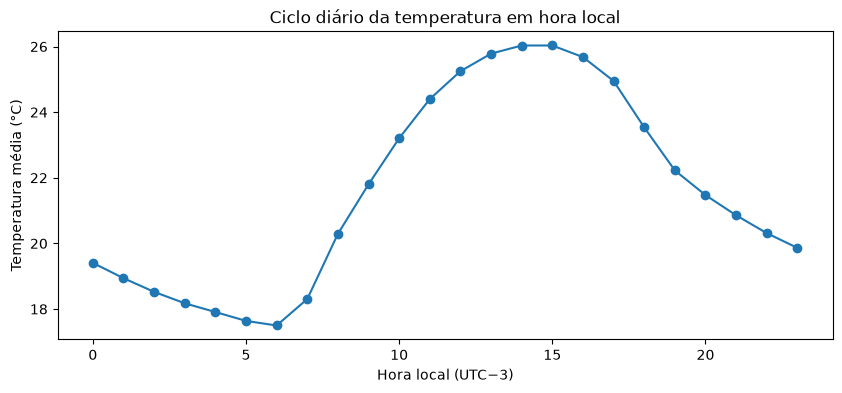

In [7]:
ax = temp_hora.plot(marker="o")
ax.set_xlabel("Hora local (UTC−3)")
ax.set_ylabel("Temperatura média (°C)")
ax.set_title("Ciclo diário da temperatura em hora local")
plt.show()

## 4. Acréscimo: calendário e variáveis derivadas

- `ano`, `mes`, `hora`, `data` em hora local;
- `estacao`: mesma regra da EDA (verão = dez–fev, outono = mar–mai, inverno = jun–ago, primavera = set–nov);
- `periodo`: **seco** (mai–set) ou **chuvoso** (out–abr). A EDA mostrou que a chuva e a umidade em Brasília seguem
  muito mais essa divisão do que as quatro estações astronômicas;
- `ponto_orvalho` (°C): temperatura em que o ar saturaria, calculada pela fórmula de Magnus
  (b = 17,62; c = 243,12 °C) a partir de temperatura e umidade. É uma medida da quantidade absoluta de vapor no ar,
  útil para separar "ar seco" de "ar quente" — algo que a umidade relativa sozinha mistura.

In [8]:
def estacao(mes):
    if mes in (12, 1, 2):
        return "Verão"
    if mes in (3, 4, 5):
        return "Outono"
    if mes in (6, 7, 8):
        return "Inverno"
    return "Primavera"


def ponto_de_orvalho(temperatura, umidade, b=17.62, c=243.12):
    gama = np.log(umidade / 100) + b * temperatura / (c + temperatura)
    return c * gama / (b - gama)


df["ano"] = df["data_hora"].dt.year
df["mes"] = df["data_hora"].dt.month
df["hora"] = df["data_hora"].dt.hour
df["data"] = df["data_hora"].dt.date
df["estacao"] = df["mes"].map(estacao)
df["periodo"] = np.where(df["mes"].between(5, 9), "Seco (mai–set)", "Chuvoso (out–abr)")
df["ponto_orvalho"] = ponto_de_orvalho(df["temperatura"], df["umidade"]).round(1)

df[["temperatura", "umidade", "precipitacao", "ponto_orvalho"]].describe().round(2)

,temperatura,umidade,precipitacao,ponto_orvalho
count,87579.00,87559.00,87558.00,87559.00
mean,21.59,64.43,0.16,13.55
std,3.93,21.46,1.37,4.40
min,5.30,10.00,0.00,-6.80
25%,18.90,48.00,0.00,10.30
50%,21.10,66.00,0.00,14.80
75%,24.40,83.00,0.00,17.20
max,35.50,100.00,62.80,22.20


### Checagens rápidas do dado tratado

- cada hora local aparece uma única vez;
- as horas que faltam (sem temperatura no arquivo original) são poucas e ficam explícitas;
- a umidade está entre 0 e 100 % e a chuva é não negativa.

In [9]:
horas_esperadas = pd.date_range(df["data_hora"].min(), df["data_hora"].max(), freq="h")
print("horas duplicadas:", df["data_hora"].duplicated().sum())
print("horas sem registro no período:", len(horas_esperadas) - len(df))
print("umidade fora de [0, 100]:", (~df["umidade"].dropna().between(0, 100)).sum())
print("chuva negativa:", (df["precipitacao"] < 0).sum())
df.groupby("periodo")[["temperatura", "umidade", "precipitacao"]].mean().round(2)

horas duplicadas: 0
horas sem registro no período: 66
umidade fora de [0, 100]: 0
chuva negativa: 0


,temperatura,umidade,precipitacao
periodo,,,
Chuvoso (out–abr),22.16,71.68,0.26
Seco (mai–set),20.79,54.38,0.02


## 5. Exportação para o app

O app lê **somente** `data/clean/dataset.csv`. Exporto só as colunas que ele usa (o dado é público: medições
meteorológicas de uma estação oficial, sem nenhuma informação pessoal).

In [10]:
COLUNAS_APP = [
    "data_hora", "data", "ano", "mes", "hora", "estacao", "periodo",
    "temperatura", "umidade", "precipitacao", "ponto_orvalho",
]
df_limpo = df[COLUNAS_APP].sort_values("data_hora").reset_index(drop=True)
df_limpo.to_csv(CAMINHO_LIMPO, index=False)
print(CAMINHO_LIMPO.relative_to(RAIZ).as_posix(), df_limpo.shape)
df_limpo.head()

data/clean/dataset.csv (87579, 11)


,data_hora,data,ano,mes,hora,estacao,periodo,temperatura,umidade,precipitacao,ponto_orvalho
0,2014-01-01 00:00:00,2014-01-01,2014,1,0,Verão,Chuvoso (out–abr),19.9,90.0,0.0,18.2
1,2014-01-01 01:00:00,2014-01-01,2014,1,1,Verão,Chuvoso (out–abr),19.4,95.0,0.0,18.6
2,2014-01-01 02:00:00,2014-01-01,2014,1,2,Verão,Chuvoso (out–abr),18.8,97.0,0.0,18.3
3,2014-01-01 03:00:00,2014-01-01,2014,1,3,Verão,Chuvoso (out–abr),18.9,97.0,0.0,18.4
4,2014-01-01 04:00:00,2014-01-01,2014,1,4,Verão,Chuvoso (out–abr),18.9,97.0,0.0,18.4
